In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense
)

In [4]:
(X_train, y_train), (X_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


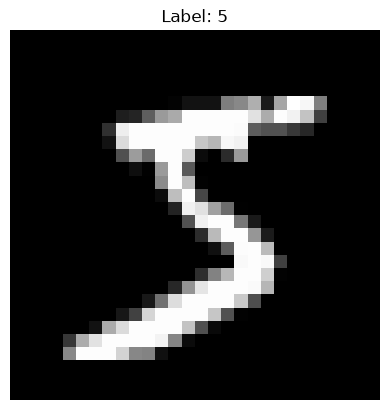

In [5]:
plt.imshow(X_train[0], cmap="gray")
plt.title(f"Label: {y_train[0]}")
plt.axis("off")
plt.show()

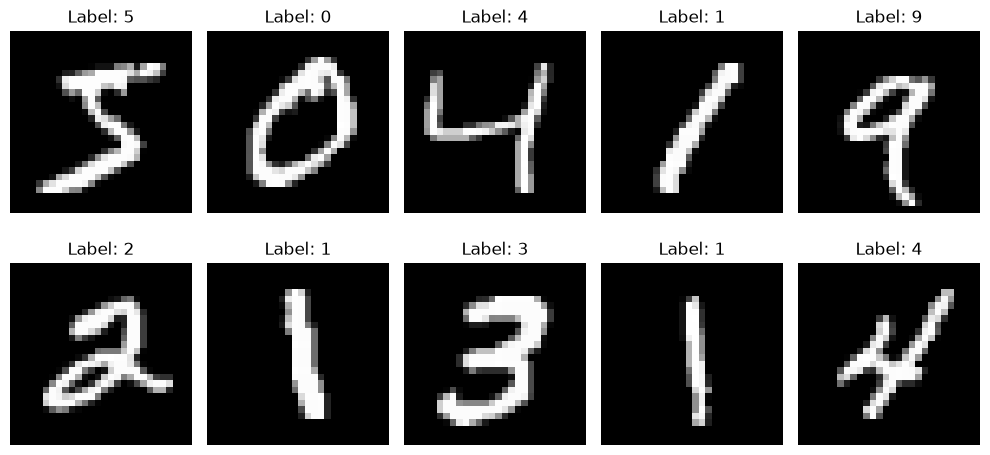

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_train[i], cmap="gray")
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
#Normalize the pixel values to the range [0, 1]
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [8]:
#Add a channel dimension to the images
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print(X_train.shape)
print(X_test.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


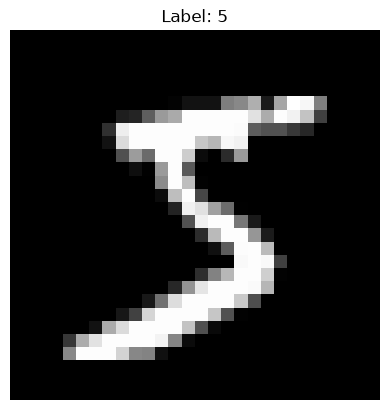

In [9]:
import matplotlib.pyplot as plt

plt.imshow(X_train[0].squeeze(), cmap="gray")
plt.title(f"Label: {y_train[0]}")
plt.axis("off")
plt.show()

In [10]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense
)

model = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),

    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),

    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),

    Dense(128, activation="relu"),

    Dense(10, activation="softmax")
])

In [11]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
#compilt the CNN model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [13]:
#train the model
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 20s 22ms/step - accuracy: 0.9501 - loss: 0.1645 - val_accuracy: 0.9855 - val_loss: 0.0496
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.9852 - loss: 0.0468 - val_accuracy: 0.9853 - val_loss: 0.0479
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.9897 - loss: 0.0318 - val_accuracy: 0.9885 - val_loss: 0.0402
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.9928 - loss: 0.0232 - val_accuracy: 0.9910 - val_loss: 0.0307
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.9944 - loss: 0.0175 - val_accuracy: 0.9898 - val_loss: 0.0338


In [14]:
#Evaluate the model on the test set
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9903 - loss: 0.0323
Test Loss: 0.03228544443845749
Test Accuracy: 0.9902999997138977


In [15]:
import numpy as np
import matplotlib.pyplot as plt

predictions = model.predict(X_test)

predicted_labels = np.argmax(predictions, axis=1)

print("Predicted labels:", predicted_labels[:10])
print("Actual labels:   ", y_test[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
Predicted labels: [7 2 1 0 4 1 4 9 5 9]
Actual labels:    [7 2 1 0 4 1 4 9 5 9]


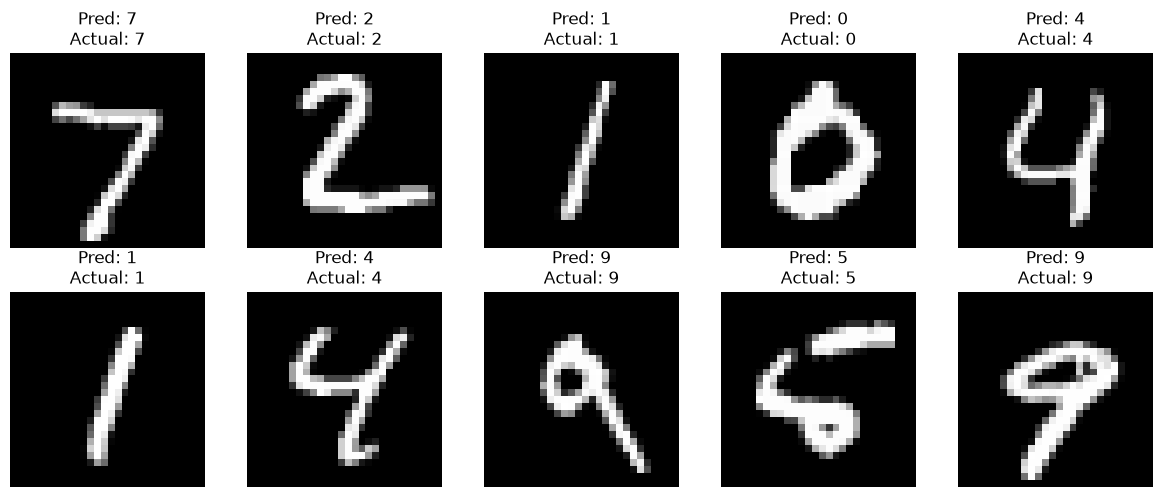

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[i].squeeze(), cmap="gray")

    plt.title(
        f"Pred: {predicted_labels[i]}\n"
        f"Actual: {y_test[i]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [17]:
# Find incorrect predictions
incorrect_indices = np.where(
    predicted_labels != y_test
)[0]

print("Number of incorrect predictions:",
      len(incorrect_indices))

Number of incorrect predictions: 97


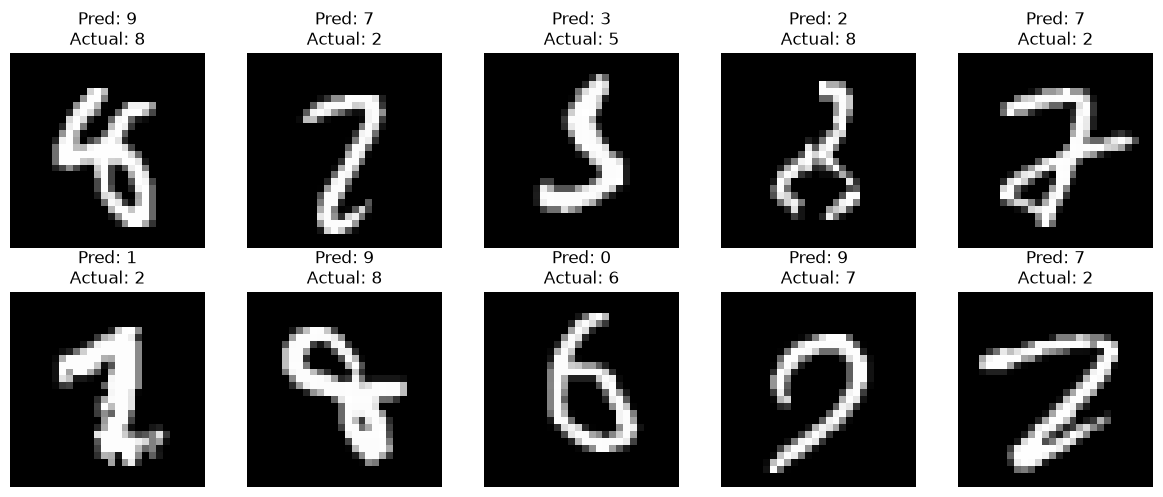

In [18]:
plt.figure(figsize=(12, 5))

for i, index in enumerate(incorrect_indices[:10]):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[index].squeeze(), cmap="gray")

    plt.title(
        f"Pred: {predicted_labels[index]}\n"
        f"Actual: {y_test[index]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:
index = incorrect_indices[0]

print("Actual label:", y_test[index])
print("Predicted label:", predicted_labels[index])

print("\nClass probabilities:")
print(predictions[index])

Actual label: 8
Predicted label: 9

Class probabilities:
[1.3171565e-06 4.8654512e-04 5.4388046e-08 1.8707746e-05 3.3011824e-02
 6.4858273e-02 2.6844746e-02 3.6357971e-08 1.1928937e-01 7.5548917e-01]


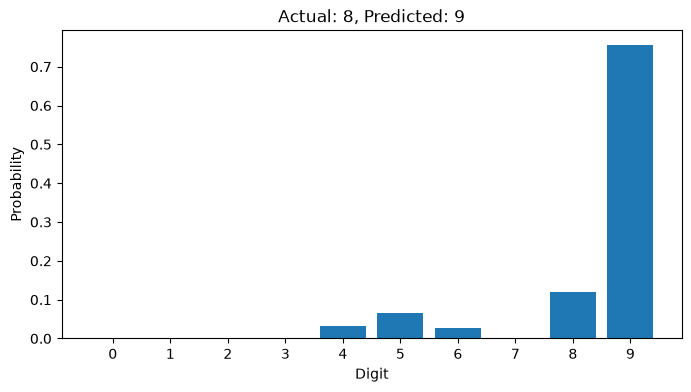

In [20]:
plt.figure(figsize=(8, 4))

plt.bar(range(10), predictions[index])

plt.xticks(range(10))
plt.xlabel("Digit")
plt.ylabel("Probability")
plt.title(
    f"Actual: {y_test[index]}, "
    f"Predicted: {predicted_labels[index]}"
)

plt.show()

In [21]:
print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


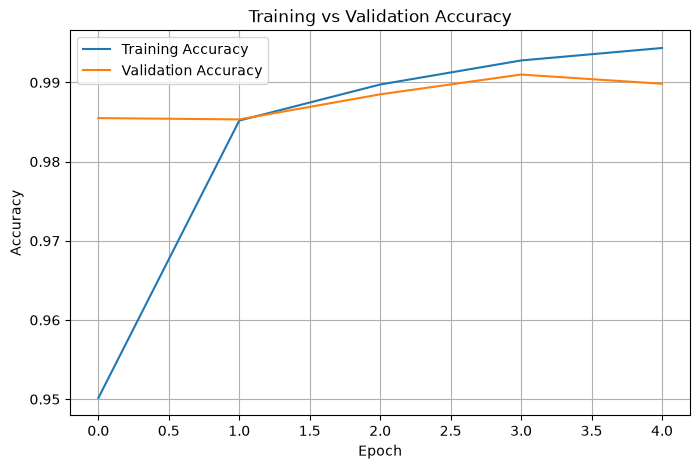

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

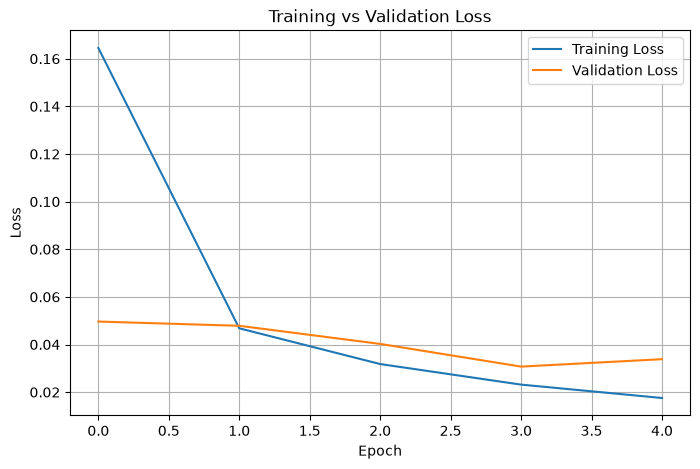

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

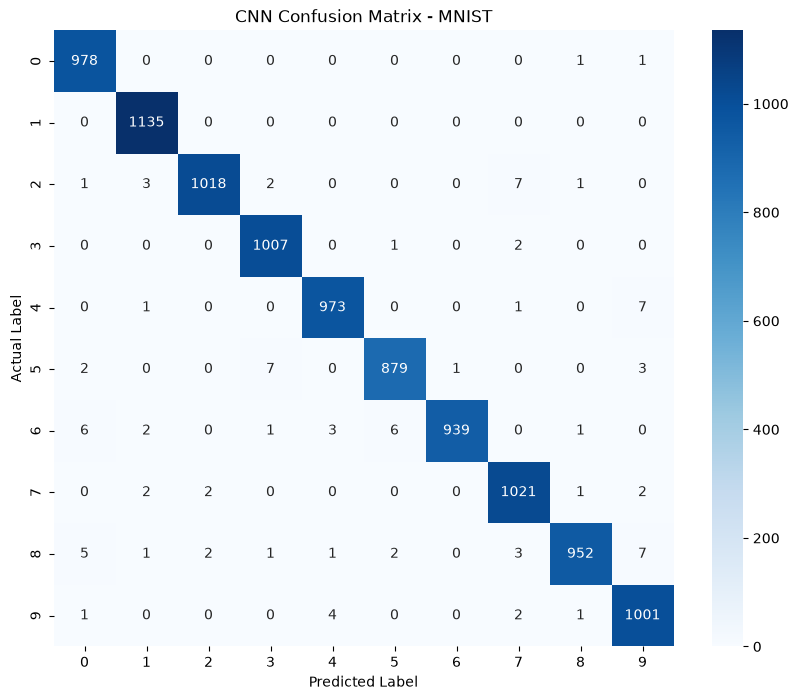

In [24]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, predicted_labels)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("CNN Confusion Matrix - MNIST")

plt.show()

In [25]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        predicted_labels
    )
)

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       980
           1       0.99      1.00      1.00      1135
           2       1.00      0.99      0.99      1032
           3       0.99      1.00      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       1.00      0.98      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      0.98      0.99       974
           9       0.98      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



In [26]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    RandomRotation,
    RandomTranslation,
    RandomZoom
)

data_augmentation = Sequential([
    RandomRotation(0.05),
    RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    ),
    RandomZoom(0.1)
])

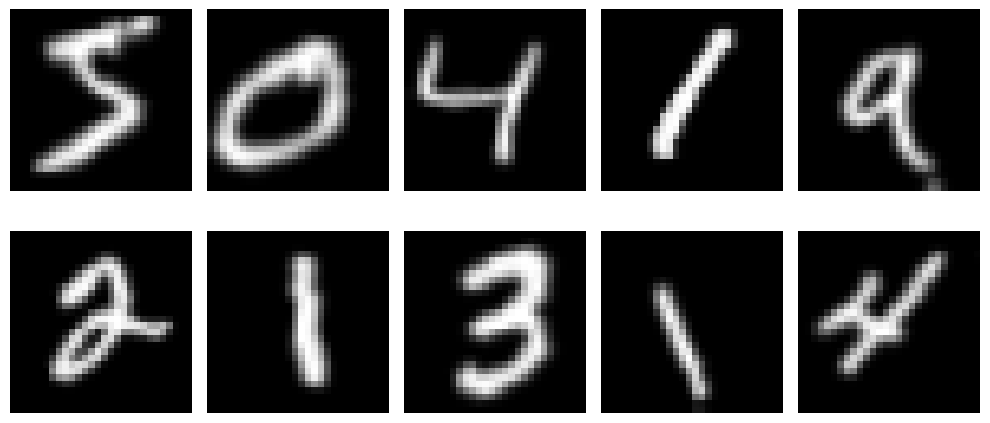

In [27]:
plt.figure(figsize=(10, 5))

for i in range(10):
    augmented_image = data_augmentation(
        X_train[i:i+1],
        training=True
    )

    plt.subplot(2, 5, i + 1)
    plt.imshow(
        augmented_image[0].numpy().squeeze(),
        cmap="gray"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [28]:
#CNN with augmentation
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    Flatten, Dense, RandomRotation,
    RandomTranslation, RandomZoom
)

model_aug = Sequential([
    Input(shape=(28, 28, 1)),

    # Data Augmentation
    RandomRotation(0.05),
    RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    ),
    RandomZoom(0.1),

    # CNN layers
    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dense(10, activation="softmax")
])

In [29]:
model_aug.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [30]:
history_aug = model_aug.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 25s 27ms/step - accuracy: 0.8975 - loss: 0.3283 - val_accuracy: 0.9798 - val_loss: 0.0643
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 23s 27ms/step - accuracy: 0.9643 - loss: 0.1137 - val_accuracy: 0.9853 - val_loss: 0.0519
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 24s 29ms/step - accuracy: 0.9743 - loss: 0.0804 - val_accuracy: 0.9897 - val_loss: 0.0376
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 24s 29ms/step - accuracy: 0.9787 - loss: 0.0681 - val_accuracy: 0.9887 - val_loss: 0.0481
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 25s 29ms/step - accuracy: 0.9809 - loss: 0.0603 - val_accuracy: 0.9892 - val_loss: 0.0473


In [31]:
test_loss_aug, test_accuracy_aug = model_aug.evaluate(
    X_test,
    y_test
)

print("Augmented CNN Test Loss:", test_loss_aug)
print("Augmented CNN Test Accuracy:", test_accuracy_aug)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9868 - loss: 0.0415
Augmented CNN Test Loss: 0.04147683084011078
Augmented CNN Test Accuracy: 0.9868000149726868


In [32]:
#Implement batch normalization in the CNN model
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    BatchNormalization,
    MaxPooling2D,
    Flatten,
    Dense
)

model_bn = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), padding="same"),
    BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), padding="same"),
    BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dense(10, activation="softmax")
])

In [33]:
BatchNormalization()

<BatchNormalization name=batch_normalization_2, built=False>

In [34]:
model_bn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [35]:
history_bn = model_bn.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 53s 58ms/step - accuracy: 0.9545 - loss: 0.1608 - val_accuracy: 0.9837 - val_loss: 0.0529
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 46s 54ms/step - accuracy: 0.9838 - loss: 0.0516 - val_accuracy: 0.9852 - val_loss: 0.0564
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 46s 54ms/step - accuracy: 0.9879 - loss: 0.0376 - val_accuracy: 0.9850 - val_loss: 0.0442
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 46s 54ms/step - accuracy: 0.9900 - loss: 0.0307 - val_accuracy: 0.9777 - val_loss: 0.0797
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 47s 56ms/step - accuracy: 0.9922 - loss: 0.0237 - val_accuracy: 0.9898 - val_loss: 0.0359


In [36]:
test_loss_bn, test_accuracy_bn = model_bn.evaluate(
    X_test,
    y_test
)

print("BatchNorm CNN Test Loss:", test_loss_bn)
print("BatchNorm CNN Test Accuracy:", test_accuracy_bn)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9891 - loss: 0.0347
BatchNorm CNN Test Loss: 0.034674324095249176
BatchNorm CNN Test Accuracy: 0.9890999794006348
